In [5]:
# Import libraries
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay,accuracy_score,classification_report

In [6]:
# Load dataset
data=pd.read_excel("crop_recommendation(  FAO).xlsx")

In [7]:
data

,N,P,K,ph,label
0,144,45,45,6.21,maize
1,91,34,34,6.55,maize
2,114,61,34,6.43,maize
3,100,38,45,5.94,maize
4,117,33,66,7.19,maize
...,...,...,...,...,...
6395,165,89,125,5.67,tomato
6396,147,88,90,7.11,tomato
6397,166,65,123,6.84,tomato
6398,119,97,110,6.42,tomato


In [8]:
# Shape of dataset
data.shape

(6400, 5)

In [9]:
# Dataset columns info
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6400 entries, 0 to 6399
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   N       6400 non-null   int64  
 1   P       6400 non-null   int64  
 2   K       6400 non-null   int64  
 3   ph      6400 non-null   float64
 4   label   6400 non-null   object 
dtypes: float64(1), int64(3), object(1)
memory usage: 250.1+ KB


In [10]:
# Check data inconsistence
data["label"].value_counts()

label
maize             200
rice              200
wheat             200
sorghum           200
millet            200
teff              200
cassava           200
sweet_potato      200
irish_potato      200
yam               200
beans             200
cowpea            200
groundnut         200
soybean           200
sesame            200
pigeon_pea        200
coffee_arabica    200
coffee_robusta    200
tea               200
cocoa             200
cotton            200
sisal             200
sugarcane         200
tobacco           200
banana            200
mango             200
papaya            200
avocado           200
cashew            200
watermelon        200
onion             200
tomato            200
Name: count, dtype: int64

In [11]:
# check impossible values
for col in data.select_dtypes(include="number").columns:
    a=data[col]<0
    if a.sum()>0:
        print(data.loc[a,col])
    else:continue

In [12]:
# Check duplicated values
data.duplicated().sum()

np.int64(0)

In [13]:
# check missing values
data.isnull().sum()

N        0
P        0
K        0
ph       0
label    0
dtype: int64

DESCRIPTIVE DATA ANALYSIS

In [14]:
# numerical analysis
data.describe()

,N,P,K,ph
count,6400.000000,6400.000000,6400.000000,6400.000000
mean,72.523594,41.511250,55.701406,6.244158
std,38.845904,18.980736,29.634103,0.758244
min,5.000000,7.000000,7.000000,4.110000
25%,41.000000,28.000000,34.000000,5.720000
50%,67.000000,39.000000,49.000000,6.230000
75%,101.000000,53.000000,73.000000,6.790000
max,189.000000,102.000000,157.000000,8.400000


In [15]:
# categoricl analysis
data.describe(include="object")

,label
count,6400
unique,32
top,maize
freq,200


In [16]:
pivot_table=data.groupby(["label"])[["N","P"]].agg('sum')
pivot_table.sort_values(by="N",ascending=False)

,N,P
label,,
sugarcane,30624,10826
tomato,27621,15225
cotton,24745,9223
tea,24391,5849
maize,23789,9925
coffee_robusta,22126,6128
banana,21797,16479
irish_potato,19904,12970
coffee_arabica,19795,4981


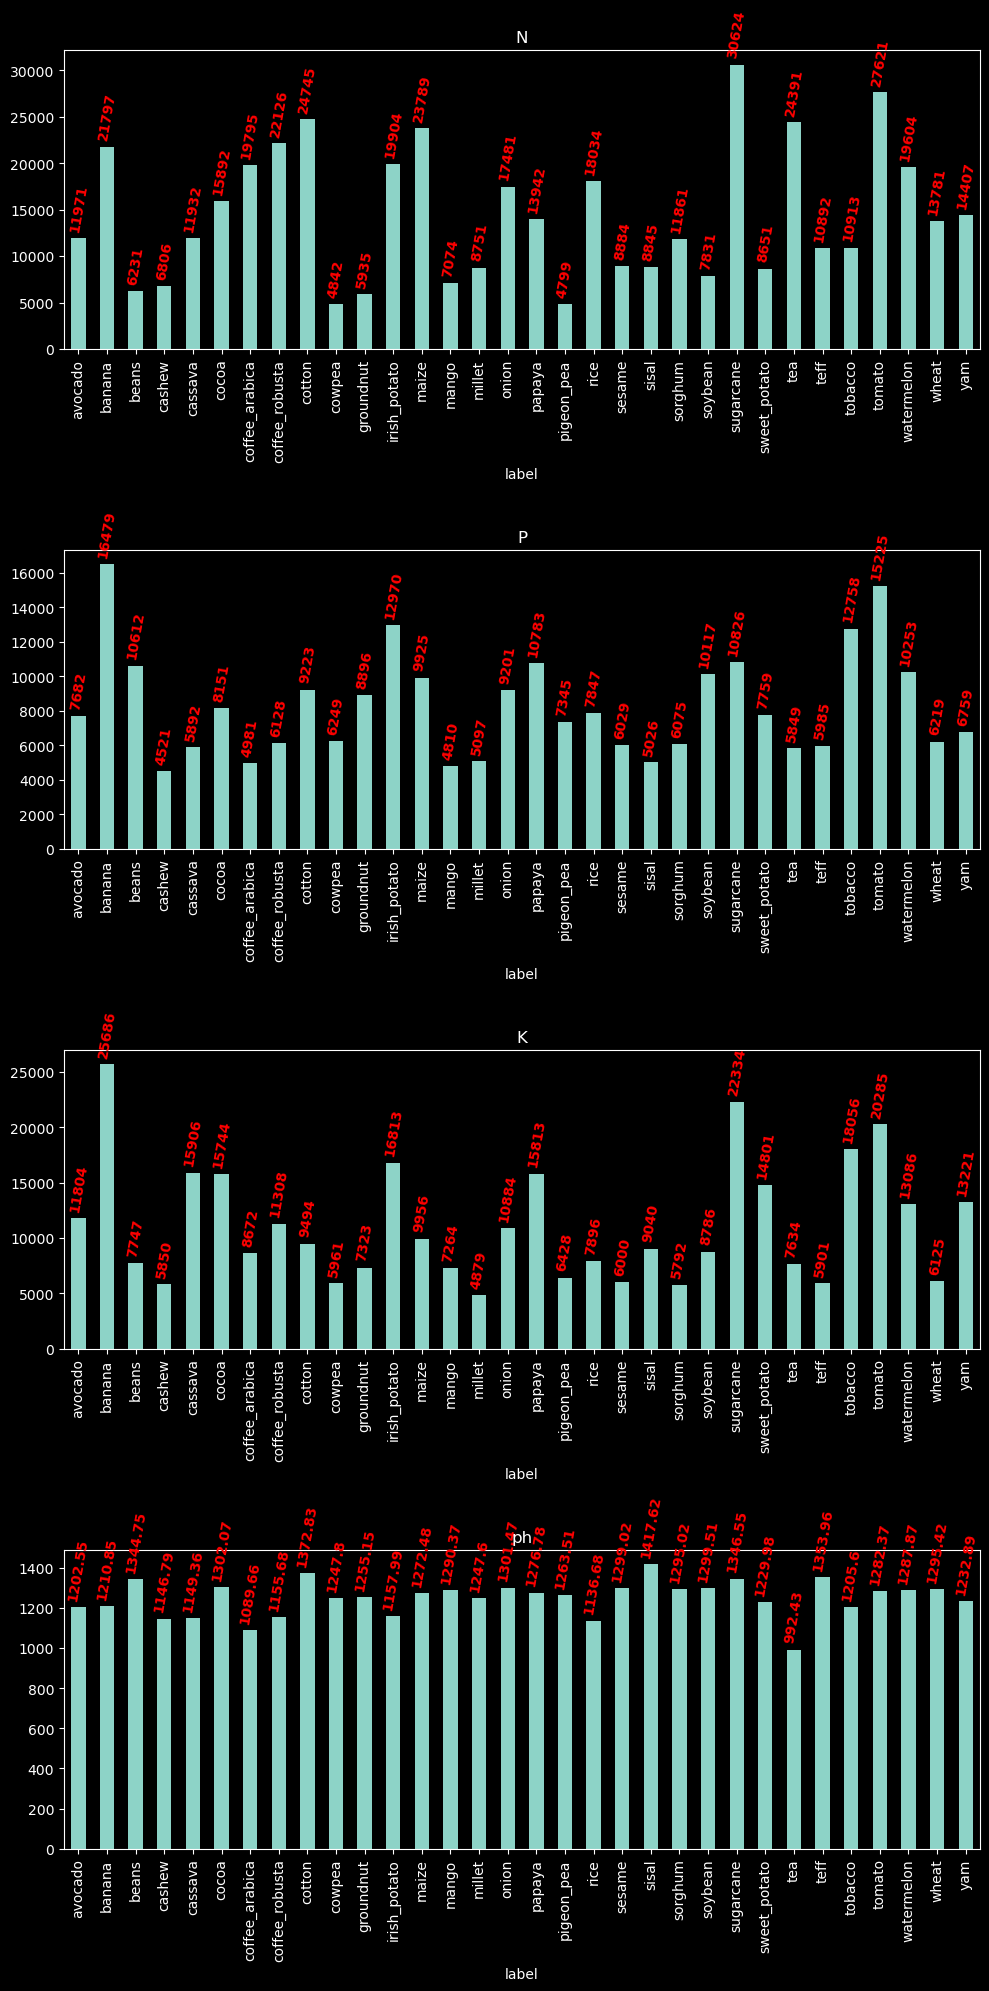

In [17]:
fig,ax=plt.subplots(4,1,figsize=(10,20))
ax=ax.flatten()
ax
for i,col in enumerate(data.select_dtypes(include="number").columns):
    pivot_table=data.groupby("label")[col].sum()
    val=pivot_table.plot(
        kind="bar",
        ax=ax[i]
    )
    for label in val.containers:
            val.bar_label(label,
                          rotation=80,
                          padding=4,
                          color="red",
                          fontweight="bold")
    ax[i].set_title(col)
    plt.tight_layout()
plt.show()

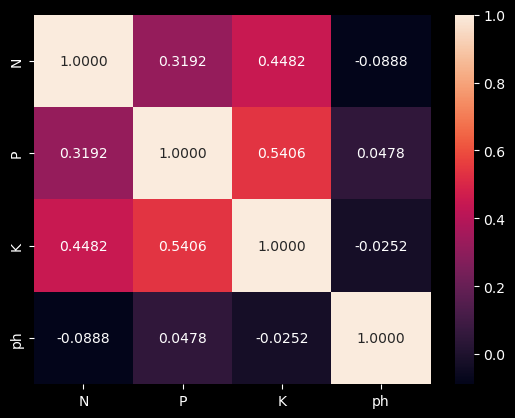

In [18]:
# Heatmap
corr_=data[[col for col in data.select_dtypes(include="number").columns]].corr()
sns.heatmap(
    corr_,
    annot=True,
    fmt=".4f"
)
plt.show()

TRAINING

In [19]:
# separate feature and target
feature=data.drop(columns="label")
target=data["label"]

In [20]:
encoder=LabelEncoder()
target=encoder.fit_transform(target)

In [21]:
# split train and test dataset
x_train,x_test,y_train,y_test=train_test_split(
    feature,
    target,
    random_state=43,
    test_size=0.2,
    stratify=target
)

In [22]:
# preprocessing
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [25]:
# Train
table_=[]
for k in range(1,100):
    model=KNeighborsClassifier(n_neighbors=k)
    score=cross_val_score(
        model,
        x_train_scaled,
        y_train,
        cv=5
    )
    table_.append({
        "k":k,
        "score":score,
        "cv_score_mean":score.mean(),
        "cv_score_std":score.std()
    })
table_score=pd.DataFrame(table_)

In [ ]:
parameter={
    "n_neighbors":[x for x in range(1,100)],
    "weights":["uniform","distance"],
    "metric":["euclidean","manhattan"]
}
modell=KNeighborsClassifier()
grid=GridSearchCV(
    estimator=modell,
    param_grid=parameter,
    cv=5,
    scoring="accuracy"
)

In [ ]:
grid.fit(x_train_scaled,y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'metric': ['euclidean', 'manhattan'],
                         'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                         13, 14, 15, 16, 17, 18, 19, 20, 21, 22,
                                         23, 24, 25, 26, 27, 28, 29, 30, ...],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [ ]:
grid.best_params_

{'metric': 'manhattan', 'n_neighbors': 74, 'weights': 'distance'}

In [ ]:
table_score["cv_score_mean"].max()

0.3701171875

In [ ]:
y_train_predict=model.predict(x_train_scaled)

In [ ]:
y_train_predict

array([25, 11, 15, ..., 23, 14,  6])

In [ ]:
y_train

array([25, 11, 29, ..., 23, 30,  6])

In [ ]:
accuracy_score(y_train,y_train_predict)

0.553125

In [ ]:
# train final model
final_model=KNeighborsClassifier(
    weights="distance",
    n_neighbors=74,
    metric="manhattan"
)
final_model.fit(x_train_scaled,y_train)

KNeighborsClassifier(metric='manhattan', n_neighbors=74, weights='distance')

In [ ]:
y_pred=final_model(x_train_scaled)

In [ ]:
accuracy_score(y_train,y_pred)

0.9998046875

In [ ]:
y_test_pred=final_model.predict(x_test_scaled)
accuracy_score(y_test,y_test_pred)

0.39140625